<a href="https://colab.research.google.com/github/kokilahemachandra-afk/srilanka-ntl-midterm/blob/main/notebooks/03_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Spatial analysis of night-time lights across Sri Lanka's DS divisions

**Research question:** Did economic activity, measured by night-time lights,
converge across Sri Lanka's 339 DS divisions between 2014 and 2025, and is it
clustered in space?

**Methods** (from the geo4bolivia articles, applied to Sri Lanka):
1. Spatial dependence: global Moran's I and local clusters (LISA)
2. Convergence: β-convergence (do dimmer divisions grow faster?) and σ-convergence (do gaps narrow?)
3. Regional inequality: Theil index, split into between and within provinces

**Input:** `data/processed/lka_ds339_ntl_annual.csv` and the boundaries in `data/boundaries/`.

## Setup
geo4bolivia was written for Bolivia, but its functions work on any table with
a `geo_id` column if we give them the boundaries (`gdf=`).

In [ ]:
!pip install -q geo4bolivia

In [ ]:
import pandas as pd, geopandas as gpd
import geo4bolivia as geo

REPO = "https://raw.githubusercontent.com/kokilahemachandra-afk/srilanka-ntl-midterm/main/"
NAME = "lka_admin3"
annual = pd.read_csv(REPO + "data/processed/lka_ds339_ntl_annual.csv")

shp = gpd.read_file(REPO + "data/boundaries/" + NAME + ".shp")
gdf = shp.rename(columns={"adm3_pcode": "geo_id", "adm3_name": "name"})[["geo_id", "name", "geometry"]]

geo.labels(annual, own={"ntl_mean": "Night-time light (total radiance)",
                        "ntl_mean": "Night-time light (mean radiance)"})

print(annual.shape, "| DS divisions:", annual["geo_id"].nunique(), "| boundaries:", len(gdf))

(4068, 11) | DS divisions: 339 | boundaries: 339


## Method 1 · Is night-time light clustered in space?


### The map
Divisions grouped into 5 classes by natural breaks (similar values together).

In [ ]:
map25 = gdf.merge(annual[annual["year"] == 2025], on="geo_id")
geo.map(map25, "ntl_mean", scheme="quantiles", k=5,
        title="Mean night-time light by DS division, 2025 (quintiles)",
        center={"lat": 7.85, "lon": 80.7}, zoom=6.3, height=700)

### Global Moran's I
Do neighbouring divisions have more similar light than chance would give?
Moran's I is near 0 with no pattern and positive when similar values cluster.
Neighbours = divisions sharing a border (queen contiguity). `p_sim` comes from
999 random reshuffles of the values over the map.

In [ ]:
mor = geo.moran(annual, "ntl_mean", year="all", gdf=gdf)
mor.df.round(3)

,year,moran_i,z_sim,p_sim,n_obs
0,2014,0.638,22.713,0.001,339
1,2015,0.626,22.381,0.001,339
2,2016,0.647,22.439,0.001,339
3,2017,0.646,22.603,0.001,339
4,2018,0.639,22.518,0.001,339
5,2019,0.633,22.315,0.001,339
6,2020,0.654,22.370,0.001,339
7,2021,0.665,22.420,0.001,339
8,2022,0.660,22.420,0.001,339
9,2023,0.659,22.366,0.001,339


### Local clusters (LISA)
Where are the clusters? **High-High**: bright divisions surrounded by bright
ones (hot spots). **Low-Low**: dim among dim (cold spots). The other two types
are outliers that differ from their neighbours.

In [ ]:
lisa = geo.lisa(annual, "ntl_mean", year=2025, gdf=gdf)
print(lisa.interpret())
lisa.fig

Local Moran statistics (LISA) locate *where* **Night-time light (mean radiance)** in 2025 clusters or stands out, under queen contiguity (1 island(s) attached to nearest neighbor), row-standardized, n=339. The accompanying global Moran's I is 0.632 (pseudo p = 0.001), consistent with overall clustering of similar values.

At the 0.05 significance level, 115 of 339 units show significant local association: **22 High-High** hot spots (high values surrounded by high neighbors) and **93 Low-Low** cold spots (low surrounded by low) mark clustering, while **0 High-Low** and **0 Low-High** units are spatial outliers that break with their surroundings. The remaining 224 units are not significant — their local pattern is compatible with randomness.

LISA pseudo p-values are computed unit by unit without a multiple-testing adjustment, so treat borderline clusters cautiously and read the map as descriptive of where dependence concentrates.

_These are associations, not causal effects. A causal re

In [ ]:
# Which provinces hold the clusters?
where = lisa.df.merge(annual[annual["year"] == 2025][["geo_id", "province"]], on="geo_id")
pd.crosstab(where["province"], where["cluster"])

cluster,High-High,Low-Low,Not significant
province,,,
Central,0,10,31
Eastern,0,10,34
North Central,0,22,7
North Western,1,4,41
Northern,0,15,19
Sabaragamuwa,0,10,19
Southern,0,5,45
Uva,0,16,10
Western,21,1,18


### σ-convergence chart (spread of log light by year)

/usr/local/lib/python3.13/dist-packages/geo4bolivia/convergence.py:295: AnalysisWarning:

sigma_convergence: log 'ntl_mean' has negative values (units below 1 in levels); the Gini index is undefined on them and was set to NaN

/usr/local/lib/python3.13/dist-packages/geo4bolivia/convergence.py:295: AnalysisWarning:

sigma_convergence: a period mean of log 'ntl_mean' is not strictly positive; the coefficient of variation is undefined and was set to NaN



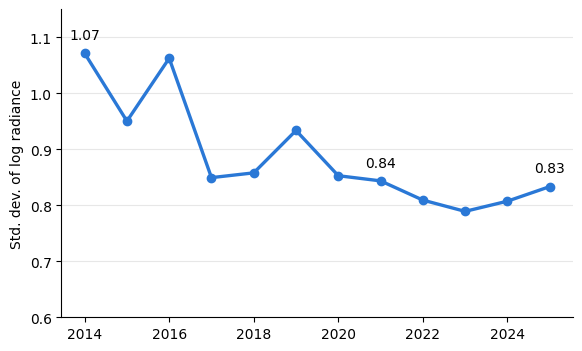

In [ ]:
import matplotlib.pyplot as plt

sigma = geo.sigma_convergence(annual, "ntl_mean")
sd = sigma.df                                  # one row per year, column "std"

fig, ax = plt.subplots(figsize=(6.6, 4.0))
ax.plot(sd["year"], sd["std"], color="#2a78d6", lw=2.4, marker="o")
for yr in (2014, 2021, 2025):                  # label three key years
    v = float(sd.loc[sd["year"] == yr, "std"].iloc[0])
    ax.annotate(f"{v:.2f}", (yr, v), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_ylabel("Std. dev. of log radiance")
ax.set_xticks(range(2014, 2026, 2))
ax.set_ylim(0.6, 1.15)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.savefig("sigma.png", dpi=200, bbox_inches="tight")
plt.show()

### Theil decomposition chart (between and within provinces)

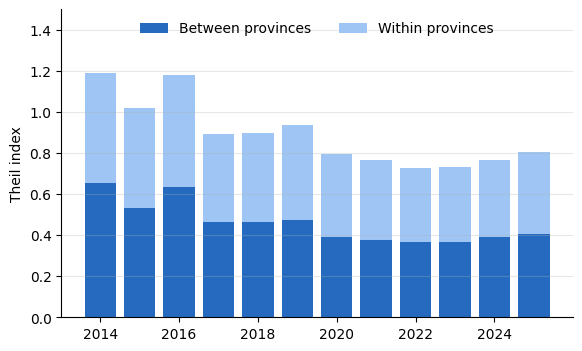

    year  theil  between_share
0   2014   1.19           0.55
1   2015   1.02           0.52
2   2016   1.18           0.54
3   2017   0.89           0.52
4   2018   0.90           0.52
5   2019   0.94           0.51
6   2020   0.80           0.49
7   2021   0.77           0.49
8   2022   0.73           0.50
9   2023   0.73           0.50
10  2024   0.76           0.51
11  2025   0.80           0.50


In [ ]:
theil = geo.theil_decomposition(annual, "ntl_mean", by="province", permutations=99)
t = theil.df                                   # columns: year, theil, between, within, between_share

fig, ax = plt.subplots(figsize=(6.6, 4.0))
ax.bar(t["year"], t["between"], color="#256abf", label="Between provinces")
ax.bar(t["year"], t["within"], bottom=t["between"], color="#9ec5f4", label="Within provinces")
ax.set_ylabel("Theil index")
ax.set_xticks(range(2014, 2026, 2))
ax.set_ylim(0, 1.5)
ax.legend(frameon=False, loc="upper center", ncols=2)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.savefig("theil.png", dpi=200, bbox_inches="tight")
plt.show()

print(t[["year", "theil", "between_share"]].round(2))   # 2014: 1.19, 0.55 → 2025: 0.80, 0.50

## Figures for the midterm slides

This section makes every chart used in the presentation.
All figures use **mean radiance** (`ntl_mean`),
because total light grows with the size of a division (see Method 1).


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})

# A lighter copy of the boundaries, only for drawing maps faster.
# (The analysis itself always uses the full boundaries in `gdf`.)
gplot = gdf.copy()
gplot["geometry"] = gdf.to_crs(5235).simplify(150).to_crs(4326)

### Figure 1 · Where is the light? Map of mean radiance, 2025

**Why this map:** before testing anything, we need to *see* the pattern. The map
shows which DS divisions are bright (high economic activity) and which are dim.

**Why quintiles:** Colombo is far brighter than everywhere else (up to 41, against
under 1.5 for most divisions). With equal-width classes almost the whole island
falls in the lightest class. Quintiles put the same number of divisions (about 68)
in each colour, so differences outside Colombo become visible.

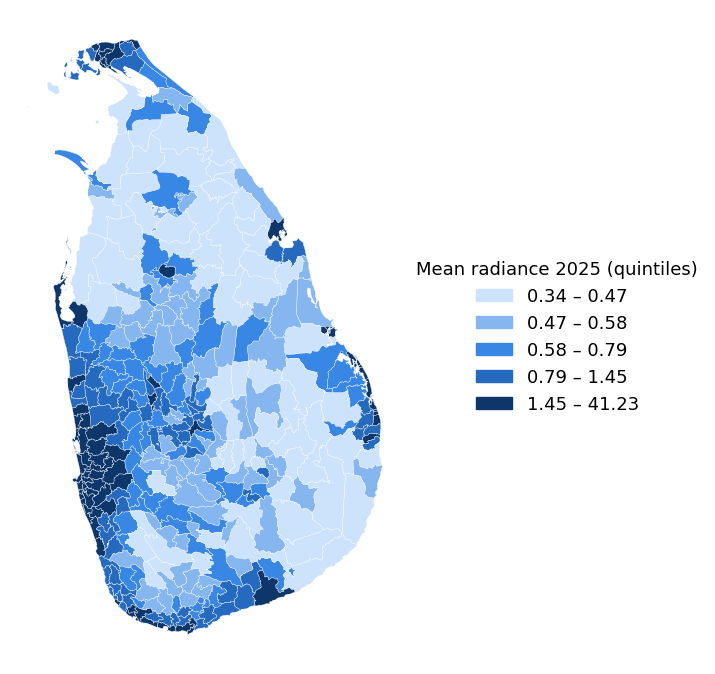

In [ ]:
m25 = gplot.merge(annual[annual["year"] == 2025], on="geo_id")
m25["quintile"] = pd.qcut(m25["ntl_mean"], 5, labels=False)      # 0 = dimmest fifth, 4 = brightest
blues = ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"]
edges = m25["ntl_mean"].quantile([0, .2, .4, .6, .8, 1]).values

fig, ax = plt.subplots(figsize=(8.5, 8.5))
m25.plot(color=m25["quintile"].map(dict(enumerate(blues))), edgecolor="white", linewidth=0.25, ax=ax)
ax.set_axis_off()
ax.legend(handles=[Patch(color=blues[i], label=f"{edges[i]:.2f} – {edges[i+1]:.2f}") for i in range(5)],
          title="Mean radiance 2025 (quintiles)", loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.savefig("fig_map_2025.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 2 · Is the light clustered? LISA cluster map, 2025

**Why this map:** Moran's I gives one number for the whole country (0.63 in 2025:
strongly clustered). LISA breaks that number down by division and shows *where*
the clusters are:
- **High-High** (red): bright divisions surrounded by bright neighbours, the hot spots
- **Low-Low** (blue): dim divisions surrounded by dim neighbours, the cold spots
- **Not significant** (grey): no clear local pattern (p ≥ 0.05)

Neighbours are divisions that share a border (queen contiguity). Significance comes
from 999 random reshuffles of the values over the map.

cluster
Not significant    224
Low-Low             93
High-High           22
Name: count, dtype: int64


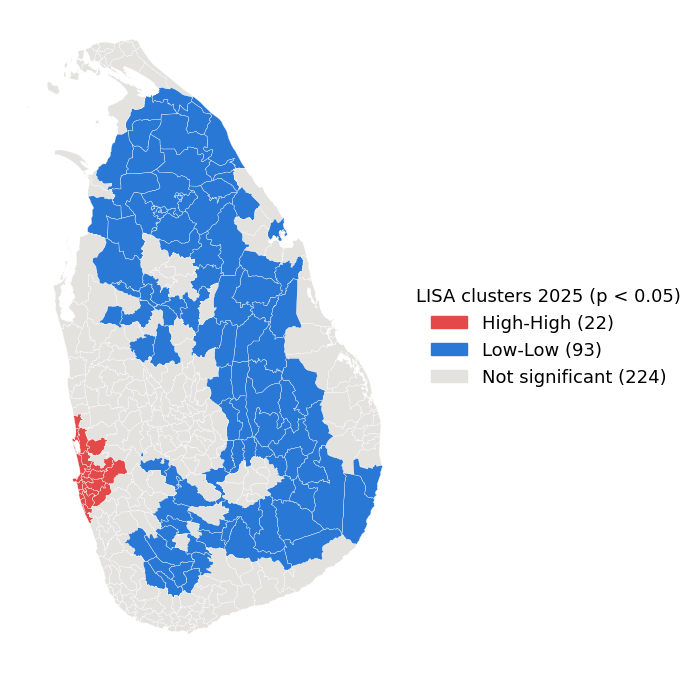

In [ ]:
lisa25 = geo.lisa(annual, "ntl_mean", year=2025, gdf=gdf)
print(lisa25.df["cluster"].value_counts())        # expect: 224 not significant, 93 Low-Low, 22 High-High

cl = gplot.merge(lisa25.df[["geo_id", "cluster"]], on="geo_id")
colours = {"High-High": "#e34948", "Low-Low": "#2a78d6", "High-Low": "#f2a7a6",
           "Low-High": "#9ec5f4", "Not significant": "#e3e2de"}
counts = cl["cluster"].value_counts()

fig, ax = plt.subplots(figsize=(8.5, 8.5))
cl.plot(color=cl["cluster"].map(colours), edgecolor="white", linewidth=0.25, ax=ax)
ax.set_axis_off()
ax.legend(handles=[Patch(color=colours[k], label=f"{k} ({counts[k]})") for k in colours if k in counts],
          title="LISA clusters 2025 (p < 0.05)", loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.savefig("fig_lisa_2025.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 3 · Did dimmer divisions grow faster? β-convergence

**Why this chart:** it tests catching up directly. Each dot is one DS division:
- horizontal axis: how bright it was at the start (log mean radiance, 2014)
- vertical axis: how fast it grew afterwards (average yearly growth, 2014–2025)

A **downward line** means divisions that started dimmer grew faster (β-convergence).

**Why highlight two provinces:** the distance of a dot from the line shows whether
a division grew faster (above) or slower (below) than its starting level predicts.
The table below averages this gap by province. Northern Province is the clearest
case above the line and Sabaragamuwa the clearest below, so they are coloured.

In [ ]:
w = annual.pivot(index="geo_id", columns="year", values="ntl_mean")
conv = pd.DataFrame({"log_start": np.log(w[2014]),
                     "growth": (np.log(w[2025]) - np.log(w[2014])) / 11 * 100})   # % per year
conv = conv.join(annual[annual["year"] == 2025].set_index("geo_id")[["province"]])

slope, intercept = np.polyfit(conv["log_start"], conv["growth"], 1)
r2 = np.corrcoef(conv["log_start"], conv["growth"])[0, 1] ** 2
print("β slope (per year):", round(slope / 100, 4), "| R²:", round(r2, 2))      # expect −0.0221, 0.65

# Above or below the line, by province
conv["residual"] = conv["growth"] - (slope * conv["log_start"] + intercept)
summary = conv.groupby("province")["residual"].agg(
    divisions="count", above_line=lambda s: (s > 0).sum(), mean_gap="mean").round(2)
print(summary.sort_values("mean_gap"))     # Northern: 34 of 34 above (+2.57); Sabaragamuwa: 1 of 29 above (−1.48)

β slope (per year): -0.0221 | R²: 0.65
               divisions  above_line  mean_gap
province                                      
Sabaragamuwa          29           1     -1.48
Southern              50          11     -0.89
Central               41          13     -0.72
Uva                   26           7     -0.57
North Western         46          28      0.22
Western               40          23      0.23
Eastern               44          23      0.32
North Central         29          18      0.40
Northern              34          34      2.57


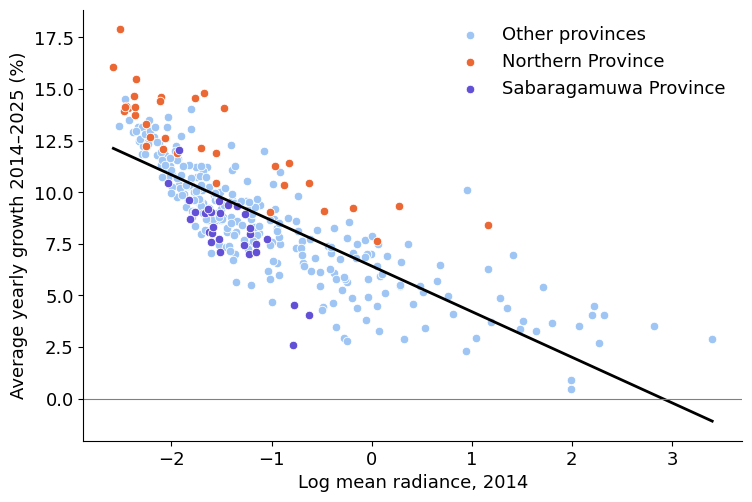

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5.6))
groups = [("Other provinces", ~conv["province"].isin(["Northern", "Sabaragamuwa"]), "#9ec5f4"),
          ("Northern Province", conv["province"] == "Northern", "#eb6834"),
          ("Sabaragamuwa Province", conv["province"] == "Sabaragamuwa", "#6250d6")]
for label, mask, colour in groups:
    ax.scatter(conv.loc[mask, "log_start"], conv.loc[mask, "growth"], s=38, color=colour,
               edgecolor="white", linewidth=0.6, label=label)

xs = np.linspace(conv["log_start"].min(), conv["log_start"].max(), 50)
ax.plot(xs, slope * xs + intercept, color="black", lw=2)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Log mean radiance, 2014")
ax.set_ylabel("Average yearly growth 2014–2025 (%)")
ax.legend(frameon=False)
plt.savefig("fig_beta.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 4 · Are the gaps narrowing? σ-convergence

**Why this chart:** β shows that dim divisions grew faster, but that does not
guarantee the gaps actually shrank, because new shocks can push divisions apart.
σ-convergence checks this directly: for each year, the standard deviation of log
light across all 339 divisions. A falling line means divisions are becoming more alike.

/usr/local/lib/python3.13/dist-packages/geo4bolivia/convergence.py:295: AnalysisWarning:

sigma_convergence: log 'ntl_mean' has negative values (units below 1 in levels); the Gini index is undefined on them and was set to NaN

/usr/local/lib/python3.13/dist-packages/geo4bolivia/convergence.py:295: AnalysisWarning:

sigma_convergence: a period mean of log 'ntl_mean' is not strictly positive; the coefficient of variation is undefined and was set to NaN



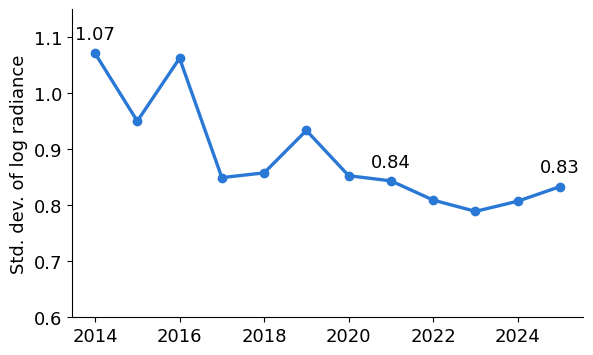

In [ ]:
sigma = geo.sigma_convergence(annual, "ntl_mean")
sd = sigma.df

fig, ax = plt.subplots(figsize=(6.6, 4.0))
ax.plot(sd["year"], sd["std"], color="#2a78d6", lw=2.4, marker="o")
for yr in (2014, 2021, 2025):
    v = float(sd.loc[sd["year"] == yr, "std"].iloc[0])
    ax.annotate(f"{v:.2f}", (yr, v), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_ylabel("Std. dev. of log radiance")
ax.set_xticks(range(2014, 2026, 2))
ax.set_ylim(0.6, 1.15)
plt.savefig("fig_sigma.png", dpi=200, bbox_inches="tight")
plt.show()

### Figure 5 · Where does the inequality sit? Theil decomposition by province

**Why this chart:** it tells us *what kind* of inequality is left. The Theil index
splits total inequality exactly into two parts:
- **Between provinces** (dark blue): provinces differ on average, e.g. Western vs Uva
- **Within provinces** (light blue): divisions differ inside the same province

If most inequality were within provinces, provincial policy would matter less.
If half is between provinces, which province a division is in still matters a lot.

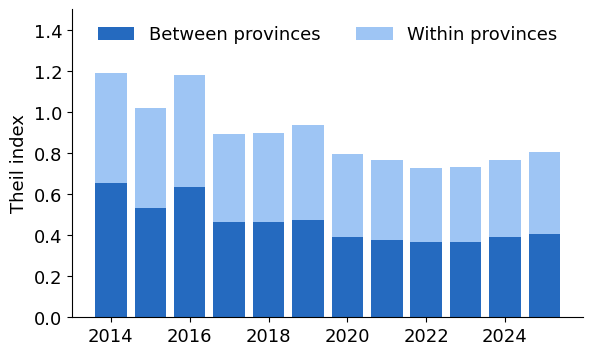

    year  theil  between_share
0   2014   1.19           0.55
1   2015   1.02           0.52
2   2016   1.18           0.54
3   2017   0.89           0.52
4   2018   0.90           0.52
5   2019   0.94           0.51
6   2020   0.80           0.49
7   2021   0.77           0.49
8   2022   0.73           0.50
9   2023   0.73           0.50
10  2024   0.76           0.51
11  2025   0.80           0.50


In [ ]:
theil = geo.theil_decomposition(annual, "ntl_mean", by="province", permutations=99)
t = theil.df

fig, ax = plt.subplots(figsize=(6.6, 4.0))
ax.bar(t["year"], t["between"], color="#256abf", label="Between provinces")
ax.bar(t["year"], t["within"], bottom=t["between"], color="#9ec5f4", label="Within provinces")
ax.set_ylabel("Theil index")
ax.set_xticks(range(2014, 2026, 2))
ax.set_ylim(0, 1.5)
ax.legend(frameon=False, loc="upper center", ncols=2)
plt.savefig("fig_theil.png", dpi=200, bbox_inches="tight")
plt.show()

print(t[["year", "theil", "between_share"]].round(2))     # 2014: 1.19, 0.55 → 2025: 0.80, 0.50

### Figure 6 · Can we trust night-time lights? A check against provincial GDP

**Why this check:** all the results above assume that night-time light measures
economic activity. Official GDP exists only for the 9 provinces, so we compare the
two there. If light tracks GDP closely at the provincial level, we can be more
confident using it for the 339 divisions, where no GDP exists.

**Why density:** we compare light per km² (mean radiance, weighted by area) with
GDP per km². Comparing totals favours large rural provinces, the same size problem
as with `ntl_sum`, so we also print the totals' correlation for contrast.

GDP source: Central Bank of Sri Lanka, Provincial GDP 2024, current market prices
(Rs. million), press release of 22 December 2025.

In [ ]:
gdp_2024 = {"Central": 3202384, "Eastern": 1496226, "North Central": 1367650,
            "North Western": 3447546, "Northern": 1321752, "Sabaragamuwa": 2288330,
            "Southern": 2672395, "Uva": 1439464, "Western": 12662817}

y24 = annual[annual["year"] == 2024].copy()
y24["light_x_area"] = y24["ntl_mean"] * y24["area_sqkm"]
prov = y24.groupby("province").agg(light_x_area=("light_x_area", "sum"),
                                   total_light=("ntl_sum", "sum"),
                                   area_km2=("area_sqkm", "sum"))
prov["light_density"] = prov["light_x_area"] / prov["area_km2"]   # area-weighted mean radiance
prov["gdp"] = pd.Series(gdp_2024)
prov["gdp_density"] = prov["gdp"] / prov["area_km2"]

r_density = np.corrcoef(np.log(prov["light_density"]), np.log(prov["gdp_density"]))[0, 1]
r_total = np.corrcoef(np.log(prov["total_light"]), np.log(prov["gdp"]))[0, 1]
print("Density: r =", round(r_density, 2), "| R² =", round(r_density**2, 2))   # expect 0.92, 0.84
print("Totals:  r =", round(r_total, 2))                                        # expect 0.61

prov.round(3).to_csv("gdp_check_2024.csv")
prov[["light_density", "gdp_density"]].round(2).sort_values("gdp_density", ascending=False)

Density: r = 0.92 | R² = 0.84
Totals:  r = 0.61


,light_density,gdp_density
province,,
Western,2.73,3403.63
Central,0.59,558.76
Southern,0.82,481.95
Sabaragamuwa,0.56,462.77
North Western,0.72,427.44
Uva,0.45,166.80
Eastern,0.53,155.09
Northern,0.53,146.25
North Central,0.47,127.96


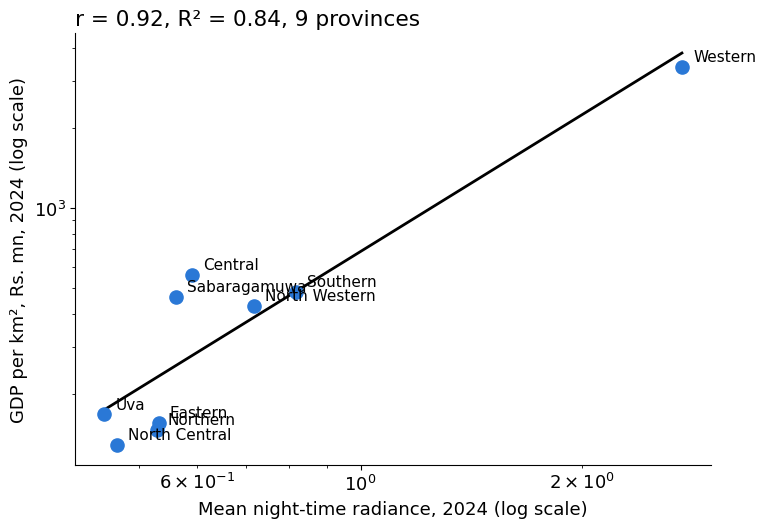

In [ ]:
fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.scatter(prov["light_density"], prov["gdp_density"], s=90, color="#2a78d6", zorder=3)
for name, row in prov.iterrows():
    ax.annotate(name, (row["light_density"], row["gdp_density"]),
                textcoords="offset points", xytext=(8, 4), fontsize=11)
ax.set_xscale("log"); ax.set_yscale("log")

b, c = np.polyfit(np.log(prov["light_density"]), np.log(prov["gdp_density"]), 1)
xs = np.linspace(prov["light_density"].min(), prov["light_density"].max(), 50)
ax.plot(xs, np.exp(c) * xs ** b, color="black", lw=2)
ax.set_xlabel("Mean night-time radiance, 2024 (log scale)")
ax.set_ylabel("GDP per km², Rs. mn, 2024 (log scale)")
ax.set_title(f"r = {r_density:.2f}, R² = {r_density**2:.2f}, 9 provinces", loc="left")
plt.savefig("fig_gdp_check.png", dpi=200, bbox_inches="tight")
plt.show()

## Summary of initial results (mean night-time light, 339 DS divisions, 2014–2025)
- **Clustering:** Moran's I = 0.64 in 2014 and 0.63 in 2025 (p = 0.001): strong and
  stable spatial clustering. LISA 2025: one hot spot (22 divisions, around Colombo,
  Western Province); cold spots (93 divisions) in North Central, Uva, Northern,
  Central, Eastern and Sabaragamuwa. Southern Province is mostly not significant.
- **β-convergence:** slope = −0.022 (R² = 0.65), half-life ≈ 27 years. Dimmer
  divisions grew faster.
- **σ-convergence:** the spread of log light fell from 1.07 (2014) to 0.83 (2025),
  with a small rise after 2023.
- **Theil:** total inequality fell from 1.19 to 0.80; about half lies between
  provinces (55% → 50%).
- **Interpretation:** catch-up is happening, but the Colombo-centred spatial
  pattern persists. All results are associations; they do not show causes.
We use mean radiance because total light grows with the size of a division.



---

